# Bab 2 — Types of Machine Learning

*Memahami Supervised Learning, Unsupervised Learning, Semi-Supervised Learning, dan Reinforcement Learning.*

Notebook ini adalah pendamping praktik untuk Bab 2 di situs **Materi Clustering**. Jalankan sel dari atas ke bawah secara berurutan (menu **Run → Run All Cells**, atau tekan `Shift + Enter` pada setiap sel).

## Tujuan pembelajaran

Setelah mengerjakan notebook ini, kamu mampu:

1. Membedakan data berlabel (*labeled data*) dan data tanpa label (*unlabeled data*).
2. Membuat model **Supervised Learning** (klasifikasi) dengan Scikit-learn.
3. Membuat model **Unsupervised Learning** (clustering dengan K-Means) dengan Scikit-learn.
4. Menjelaskan perbedaan `fit()`, `predict()`, dan `fit_predict()`.
5. Menafsirkan hasil klasifikasi dan hasil clustering.

## Pendahuluan

Machine Learning punya beberapa jenis. Dua yang paling penting untuk kita:

| Jenis | Data | Tujuan | Contoh di notebook ini |
|---|---|---|---|
| **Supervised Learning** | Fitur **dan** label | Menebak label untuk data baru | Menebak jenis bunga iris |
| **Unsupervised Learning** | Fitur saja, **tanpa** label | Menemukan kelompok atau pola | Mengelompokkan pelanggan |

- **Fitur** adalah ciri yang dipakai untuk menebak, misalnya ukuran kelopak bunga.
- **Label** adalah jawaban, misalnya jenis bunga.

Fokus kurikulum ini adalah **clustering**, yang termasuk Unsupervised Learning. Namun kita mulai dari Supervised Learning sebagai pembanding.

## 1. Mengimpor pustaka

Sel berikut mengambil semua alat yang dibutuhkan:

- `pandas` (disingkat `pd`): mengolah tabel.
- `matplotlib.pyplot` (disingkat `plt`): menggambar grafik.
- Dari `sklearn` (Scikit-learn): dataset Iris, fungsi pembagi data, algoritma KNN, fungsi akurasi, dan algoritma K-Means.

Jika muncul `ModuleNotFoundError`, pasang dulu pustakanya dengan `pip install pandas matplotlib scikit-learn`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

print("Semua pustaka berhasil diimpor.")

Semua pustaka berhasil diimpor.


---

# Bagian A — Supervised Learning: Klasifikasi Bunga Iris

**Masalah:** menebak jenis bunga iris (*setosa*, *versicolor*, atau *virginica*) dari 4 ukuran bunga.

Ini **Supervised Learning** karena setiap bunga di dataset sudah punya label jenisnya, dan **classification** karena jawabannya berupa kategori.

## A.1 Memuat dataset

- `load_iris(as_frame=True)` memuat dataset Iris yang sudah tersedia di Scikit-learn. `as_frame=True` membuat datanya berbentuk tabel pandas sehingga ada nama kolom.
- `X` berisi **fitur** (4 ukuran bunga). Huruf besar karena berupa tabel.
- `y` berisi **label** (jenis bunga dalam angka 0, 1, 2). Huruf kecil karena berupa satu kolom.

In [2]:
iris = load_iris(as_frame=True)
X = iris.data          # fitur: 4 ukuran bunga
y = iris.target        # label: jenis bunga (0, 1, 2)

## A.2 Mengenali fitur dan target

`X.head()` menampilkan 5 baris pertama. `iris.target_names` berisi nama kelas: label 0 = setosa, 1 = versicolor, 2 = virginica.

In [3]:
print(X.head())
print("Nama kelas:", iris.target_names.tolist())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Nama kelas: ['setosa', 'versicolor', 'virginica']


**Interpretasi:** ada 4 fitur dalam sentimeter: panjang dan lebar *sepal* (kelopak luar) serta panjang dan lebar *petal* (mahkota). Angka paling kiri adalah nomor baris (indeks), bukan fitur.

## A.3 Memeriksa ukuran data

`.shape` memberi ukuran `(baris, kolom)`. `value_counts()` menghitung jumlah bunga di setiap kelas.

In [4]:
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)
print("Jumlah per kelas:", y.value_counts().sort_index().tolist())

Ukuran X: (150, 4)
Ukuran y: (150,)
Jumlah per kelas: [50, 50, 50]


**Interpretasi:** 150 bunga, 4 fitur, dan setiap kelas punya 50 bunga (dataset seimbang). Jumlah baris `X` dan `y` harus sama.

## A.4 Membagi data latih dan data uji

Kita menyisihkan 20% data untuk ujian agar model diuji dengan bunga yang **belum pernah dilihatnya**.

- `test_size=0.2`: 20% untuk uji.
- `random_state=42`: mengunci pengacakan agar hasil selalu sama.
- `stratify=y`: menjaga proporsi kelas tetap sama di data latih dan uji.

Urutan hasilnya selalu: `X_train, X_test, y_train, y_test`.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Data latih: (120, 4) | Data uji: (30, 4)


## A.5 Membuat dan melatih model

- `KNeighborsClassifier(n_neighbors=5)` menyiapkan algoritma **K-Nearest Neighbors**: untuk menebak sebuah bunga, lihat 5 bunga latih yang paling mirip, lalu pilih jenis yang paling banyak.
- `model.fit(X_train, y_train)` melatih model. Perhatikan bahwa **label ikut diberikan**. Inilah ciri Supervised Learning.

In [6]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## A.6 Membuat prediksi

`model.predict(X_test)` hanya menerima **fitur**. Model harus menebak labelnya sendiri. Kita bandingkan 5 tebakan pertama dengan jawaban sebenarnya.

In [7]:
y_pred = model.predict(X_test)
print("5 prediksi pertama :", y_pred[:5].tolist())
print("5 jawaban sebenarnya:", y_test[:5].tolist())

5 prediksi pertama : [0, 2, 1, 1, 0]
5 jawaban sebenarnya: [0, 2, 1, 1, 0]


Kita juga bisa menebak bunga yang benar-benar baru. Datanya harus berupa tabel satu baris dengan nama kolom yang sama seperti data latih.

In [8]:
bunga_baru = pd.DataFrame([[5.0, 3.4, 1.5, 0.2]], columns=X.columns)
kelas_baru = model.predict(bunga_baru)[0]
print("Bunga baru diprediksi:", iris.target_names[kelas_baru])

Bunga baru diprediksi: setosa


## A.7 Evaluasi akurasi

Akurasi = jumlah tebakan benar ÷ jumlah seluruh tebakan. Urutan parameter `accuracy_score` adalah jawaban sebenarnya **dulu**, lalu tebakan.

In [9]:
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi: {akurasi:.2f}")

Akurasi: 1.00


**Interpretasi:** akurasi 1.00 berarti seluruh 30 bunga uji ditebak dengan benar. Ini terjadi karena Iris adalah dataset kecil dan rapi. Pada data nyata, akurasi 100% justru patut dicurigai.

**Kesalahan umum:**

- Memanggil `predict` sebelum `fit` menghasilkan `NotFittedError`.
- Melatih dengan data uji membuat evaluasi tidak jujur.
- Memberikan satu bunga sebagai list biasa menghasilkan error *Expected 2D array*.

---

# Bagian B — Unsupervised Learning: Clustering Pelanggan dengan K-Means

**Masalah:** sebuah toko punya data 18 pelanggan (pendapatan dan skor belanja) **tanpa label tipe pelanggan**. Apakah pelanggan-pelanggan ini membentuk kelompok?

Ini **Unsupervised Learning**: tidak ada jawaban yang diberikan, dan tujuannya **menemukan** kelompok.

> Ini demonstrasi pengantar dengan data kecil yang sengaja dibuat rapi, belum eksperimen clustering yang lengkap.

## B.1 Membuat dataset tanpa label

- `pendapatan`: juta rupiah per tahun.
- `skor_belanja`: 1–100, makin tinggi makin aktif berbelanja.

Perhatikan bahwa **tidak ada kolom label**. Kita tidak perlu label karena kita tidak menebak jawaban yang sudah diketahui, melainkan meminta algoritma menunjukkan kelompok yang ada.

In [10]:
pelanggan = pd.DataFrame({
    "pendapatan": [15, 16, 17, 18, 19, 20,      # juta rupiah per tahun
                   55, 57, 60, 62, 58, 61,
                   90, 95, 92, 98, 94, 99],
    "skor_belanja": [80, 85, 78, 90, 82, 88,    # 1-100, makin tinggi makin boros
                     50, 45, 52, 48, 55, 47,
                     15, 20, 12, 18, 10, 22],
})

## B.2 Mengenali dataset

`describe()` menghitung statistik ringkas: jumlah (`count`), rata-rata (`mean`), simpangan baku (`std`), nilai terkecil (`min`), kuartil (`25%`, `50%`, `75%`), dan nilai terbesar (`max`).

In [11]:
print(pelanggan.head())
print("Ukuran data:", pelanggan.shape)
print(pelanggan.describe().round(1))

   pendapatan  skor_belanja
0          15            80
1          16            85
2          17            78
3          18            90
4          19            82
Ukuran data: (18, 2)
       pendapatan  skor_belanja
count        18.0          18.0
mean         57.0          49.8
std          32.5          28.7
min          15.0          10.0
25%          19.2          20.5
50%          59.0          49.0
75%          91.5          79.5
max          99.0          90.0


**Interpretasi:** 18 pelanggan dan 2 fitur. Skala kedua fitur mirip (sekitar 10–100), sehingga untuk contoh ini kita tidak perlu menyamakan skala terlebih dahulu.

## B.3 Menyiapkan fitur numerik

K-Means mengukur **jarak** antar data, sehingga semua fitur harus berupa angka. Kita simpan fitur di `X_pelanggan` secara terpisah agar kolom `cluster` yang nanti ditambahkan **tidak ikut** menjadi fitur.

In [12]:
X_pelanggan = pelanggan[["pendapatan", "skor_belanja"]]

## B.4 Membuat model K-Means

- `n_clusters=3`: jumlah cluster. **Kita yang menentukan**, bukan algoritma.
- `n_init=10`: K-Means dijalankan 10 kali dengan titik awal berbeda, lalu hasil terbaik dipilih.
- `random_state=42`: mengunci pengacakan agar hasil selalu sama.

In [13]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)

## B.5 Melatih model dan mendapatkan nomor cluster

`fit_predict(X)` melatih K-Means lalu langsung mengembalikan nomor cluster untuk setiap pelanggan. Perhatikan bahwa kita hanya memberi `X`, **tanpa `y`**.

| Metode | Fungsi |
|---|---|
| `fit(X)` | Melatih model (mencari posisi pusat cluster) |
| `predict(X_baru)` | Memasukkan data ke pusat cluster terdekat, tanpa mengubah pusat |
| `fit_predict(X)` | `fit` lalu langsung mengembalikan nomor cluster untuk `X` yang sama |

In [14]:
label_cluster = kmeans.fit_predict(X_pelanggan)
pelanggan["cluster"] = label_cluster
print(pelanggan["cluster"].value_counts().sort_index())

cluster
0    6
1    6
2    6
Name: count, dtype: int64


## B.6 Pusat cluster dan pelanggan baru

`cluster_centers_` berisi posisi pusat setiap cluster. `predict` memasukkan pelanggan baru ke cluster dengan pusat terdekat.

In [15]:
pusat = pd.DataFrame(kmeans.cluster_centers_, columns=X_pelanggan.columns).round(1)
print(pusat)

pelanggan_baru = pd.DataFrame({"pendapatan": [58], "skor_belanja": [50]})
print("Pelanggan baru masuk cluster:", kmeans.predict(pelanggan_baru)[0])

   pendapatan  skor_belanja
0        58.8          49.5
1        94.7          16.2
2        17.5          83.8
Pelanggan baru masuk cluster: 0


## B.7 Visualisasi hasil clustering

Setiap titik adalah satu pelanggan, diwarnai menurut nomor cluster. Tanda **X merah** adalah pusat cluster.

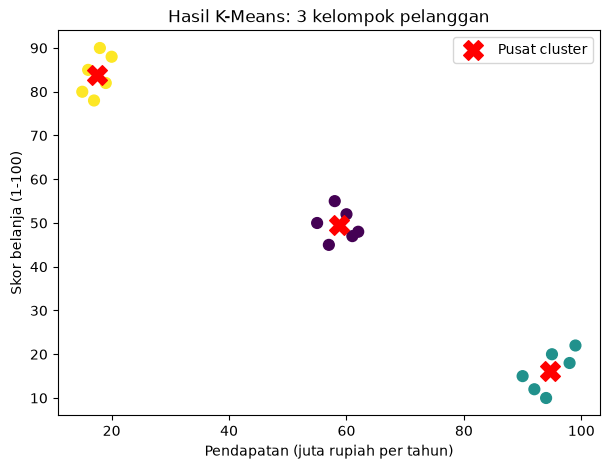

In [16]:
plt.figure(figsize=(7, 5))
plt.scatter(pelanggan["pendapatan"], pelanggan["skor_belanja"],
            c=pelanggan["cluster"], cmap="viridis", s=60)
plt.scatter(pusat["pendapatan"], pusat["skor_belanja"],
            c="red", marker="X", s=200, label="Pusat cluster")
plt.xlabel("Pendapatan (juta rupiah per tahun)")
plt.ylabel("Skor belanja (1-100)")
plt.title("Hasil K-Means: 3 kelompok pelanggan")
plt.legend()
plt.show()

## B.8 Menafsirkan kelompok

K-Means hanya memberi **nomor** cluster. Maknanya kita tentukan sendiri dengan melihat rata-rata setiap cluster.

In [17]:
print(pelanggan.groupby("cluster")[["pendapatan", "skor_belanja"]].mean().round(1))

         pendapatan  skor_belanja
cluster                          
0              58.8          49.5
1              94.7          16.2
2              17.5          83.8


**Interpretasi** (nomor cluster bisa berbeda pada versi Scikit-learn lain; perhatikan isinya):

- Pendapatan rendah, skor belanja tinggi: pelanggan yang sangat aktif berbelanja walaupun pendapatannya kecil.
- Pendapatan dan skor belanja menengah: pelanggan rata-rata.
- Pendapatan tinggi, skor belanja rendah: daya beli tinggi tetapi jarang berbelanja.

Berbeda dengan Bagian A, di sini **tidak ada akurasi**, karena tidak ada jawaban untuk dicocokkan. Evaluasi clustering memakai cara lain yang dipelajari di level selanjutnya.

**Kesalahan umum:**

- Memasukkan kolom teks ke fitur menghasilkan error konversi ke angka.
- Mengira K-Means memilih jumlah cluster sendiri. `n_clusters` selalu kita tentukan.
- Menganggap nomor cluster punya urutan nilai.

---

# Latihan

Kerjakan di sel kosong di bawah setiap soal. Kunci jawaban ada di halaman **Latihan** pada situs (Bab 2).

1. Pada Bagian A, ubah `n_neighbors=5` menjadi `1`, lalu `50`. Apa yang terjadi pada akurasi?
2. Pada Bagian A, tebak jenis bunga dengan ukuran `[6.7, 3.0, 5.2, 2.3]`.
3. Pada Bagian B, ubah `n_clusters=3` menjadi `2` dan `4`. Kelompok mana yang digabung atau dipecah? Mana yang paling masuk akal?
4. Pada Bagian B, ganti `fit_predict` dengan `fit` lalu `predict`. Apakah hasilnya sama?

In [18]:
# Latihan 1: tulis kodemu di sini

In [19]:
# Latihan 2: tulis kodemu di sini

In [20]:
# Latihan 3: tulis kodemu di sini

In [21]:
# Latihan 4: tulis kodemu di sini

---

# Ringkasan

- **Supervised Learning** memakai fitur **dan** label: `model.fit(X_train, y_train)`, lalu dievaluasi dengan membandingkan tebakan dan label, misalnya dengan akurasi.
- **Unsupervised Learning** hanya memakai fitur: `kmeans.fit_predict(X)` tanpa `y`. Hasilnya nomor cluster yang perlu ditafsirkan manusia.
- Pola umum Scikit-learn: buat model → `fit` → `predict`.
- K-Means **tidak** menentukan jumlah cluster sendiri.
- Nomor cluster hanyalah nama, bukan peringkat.

Bab berikutnya membahas lebih dalam bagaimana data disiapkan dan model dinilai, sebagai bekal sebelum eksplorasi dan pra-pemrosesan data untuk clustering.